# 2차 팀 프로젝트 (1) — 이커머스 고객 이탈 예측 : 데이터 탐색(EDA) 다시 보기

2팀 프로젝트 **ShopInsight — 고객 이탈 예측 분석 및 Streamlit 대시보드** ([팀 저장소](https://github.com/SKNETWORKS-FAMILY-AICAMP/SKN37-2ST-2TEAM))를 수업 실습 형식으로 **다시 실행하며 정리 · 점검한 노트**입니다.

- 원본 코드 · 데이터 · 모델은 [`team_project/`](./team_project/) 에 팀 저장소 구조 그대로 두었습니다 (`app.py` · `data/` · `models/`).
- 모델 학습 · 평가 · 비교는 [`churn_project_mlp.ipynb`](./churn_project_mlp.ipynb) 에 이어서 정리했습니다.
- 팀 결과와 다르거나 짚어 볼 부분은 **📝 점검** 으로 따로 적었습니다. **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.

| 항목 | 내용 |
|---|---|
| 데이터 | [Hugging Face `d0r1h/customer_churn`](https://huggingface.co/datasets/d0r1h/customer_churn) 정제본 — 36,992명 × 23열 |
| 정답 | `churn_risk_score` — 1 이탈 / 0 유지 |
| 모델 입력 | 멤버십 `membership_category` · 보유 포인트 `points_in_wallet` · 평균 거래 금액 `avg_transaction_value` · 피드백 그룹 `feedback_group` |
| 모델 | PyTorch MLP (입력 11 → 32 → 16 → 1) |
| 서비스 | Streamlit 4페이지 (핵심 지표 · 이탈 예측 · 원인 분석 · 모델 성능) |

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 데이터 불러오기 · 기본 확인

In [2]:
import numpy as np
import pandas as pd

DATA = 'team_project/data/[2nd] customer_churn_ecommerce_cleaned.csv'   # 팀 저장소 data/ 폴더 그대로
df = pd.read_csv(DATA)

# 팀 모델과 같은 피드백 그룹 : 긍정 4종 / 없음(No reason specified) / 나머지 부정 4종
POSITIVE = ['Products always in Stock', 'Quality Customer Care', 'Reasonable Price', 'User Friendly Website']
df['feedback_group'] = np.where(df['feedback'].isin(POSITIVE), 'positive',
                                np.where(df['feedback'] == 'No reason specified', 'none', 'negative'))
TARGET = 'churn_risk_score'
print(df.shape)

(36992, 24)


In [3]:
print('결측치 합계 :', df.isna().sum().sum(), '(정제본이라 이미 채워져 있음)')
print('중복 행     :', df.duplicated().sum())
print()
print('정답 분포 :', df[TARGET].value_counts().to_dict(), f'→ 이탈 비율 {df[TARGET].mean():.3f}')
df.head(3)

결측치 합계 : 0 (정제본이라 이미 채워져 있음)
중복 행     : 0

정답 분포 : {1: 20012, 0: 16980} → 이탈 비율 0.541


,age,gender,region_category,membership_category,joined_through_referral,preferred_offer_types,medium_of_operation,internet_option,days_since_last_login,avg_time_spent,...,offer_application_preference,past_complaint,complaint_status,feedback,churn_risk_score,joining_year,joining_month,last_visit_hour,last_visit_minute,feedback_group
0,18,F,Village,Platinum Membership,No,Gift Vouchers/Coupons,Unknown,Wi-Fi,17.0,300.63,...,Yes,No,Not Applicable,Products always in Stock,0,2017,8,16,8,positive
1,32,F,City,Premium Membership,Unknown,Gift Vouchers/Coupons,Desktop,Mobile_Data,16.0,306.34,...,No,Yes,Solved,Quality Customer Care,0,2017,8,12,38,positive
2,44,F,Town,No Membership,Yes,Gift Vouchers/Coupons,Desktop,Wi-Fi,14.0,516.16,...,Yes,Yes,Solved in Follow-up,Poor Website,1,2016,11,22,53,negative


In [4]:
num_cols = ['age', 'days_since_last_login', 'avg_time_spent', 'avg_transaction_value',
            'avg_frequency_login_days', 'points_in_wallet']
df[num_cols].describe().T[['min', '25%', '50%', '75%', 'max']].round(2)

,min,25%,50%,75%,max
age,10.00,23.00,37.00,51.00,64.00
days_since_last_login,1.00,9.00,13.00,16.00,26.00
avg_time_spent,1.84,75.62,174.18,356.52,3235.58
avg_transaction_value,800.46,14177.54,27554.48,40855.11,99914.05
avg_frequency_login_days,0.01,11.00,16.00,22.00,73.06
points_in_wallet,-760.66,624.35,697.62,757.00,2069.07


## 2. 데이터 품질 점검 — 정제본에 남은 흔적

In [5]:
p = df['points_in_wallet']
top = p.value_counts().head(3)
print('가장 많이 나온 포인트 값 :', top.to_dict())
print(f'→ 697.62 가 {top.iloc[0]:,}명 ({top.iloc[0] / len(df):.1%}) — 중앙값 {p.median()} 과 같다 = 결측을 중앙값으로 채운 자리')
print(f'음수 포인트 : {(p < 0).sum()}명 (최솟값 {p.min()})')
print()
filled = p == 697.62
print('이탈 비율 — 중앙값으로 채운 고객 %.3f / 나머지 %.3f' % (df.loc[filled, TARGET].mean(), df.loc[~filled, TARGET].mean()))

가장 많이 나온 포인트 값 : {697.62: 3446, 705.07: 9, 780.92: 8}
→ 697.62 가 3,446명 (9.3%) — 중앙값 697.62 과 같다 = 결측을 중앙값으로 채운 자리
음수 포인트 : 136명 (최솟값 -760.6612363)

이탈 비율 — 중앙값으로 채운 고객 0.544 / 나머지 0.541


> **📝 점검**
> - 포인트 결측을 **중앙값(697.62)** 으로 채워 같은 값이 **3,446명(9.3%)** 에 몰려 있다 (Hugging Face 원본의 결측 3,443명 + 원래 697.62 였던 3명). 이 고객들의 이탈률은 54% 로 전체 평균과 같다 — 모델이 이 값에서 아무 정보도 얻지 못한다. 결측 여부를 따로 표시하는 열(`points_missing`)을 두면 '결측' 자체를 정보로 쓸 수 있다 (`SimpleImputer(add_indicator=True)`)
> - 포인트가 **음수**인 고객이 136명 남아 있다(원본 그대로). 정제 때 음수 · −999 · `Error` 를 결측으로 바꾼 열은 `days_since_last_login`(−999 1,999명) · `avg_time_spent`(음수 1,719명) · `avg_frequency_login_days`(`Error` 3,522 · 음수 683명)이고 **포인트는 빠졌다**
> - `avg_frequency_login_days` 도 같은 이유로 중앙값 **16.0 에 5,524명**이 몰려 있다 (원본에서 16.0 은 1,319명)

## 3. 범주형 — 멤버십 · 피드백별 이탈률

![이탈률 애니메이션](./images/anim_01_churn_rate_bars.gif)

In [6]:
def rate_table(col):
    t = df.groupby(col)[TARGET].agg(고객수='size', 이탈률='mean')
    return t.sort_values('이탈률', ascending=False).round(3)

display(rate_table('membership_category'))
display(rate_table('feedback'))
rate_table('feedback_group')

,고객수,이탈률
membership_category,,
No Membership,7692,0.971
Basic Membership,7724,0.968
Silver Membership,5988,0.428
Gold Membership,6795,0.370
Platinum Membership,4338,0.000
Premium Membership,4455,0.000


,고객수,이탈률
feedback,,
Poor Product Quality,6350,0.650
Poor Customer Service,6252,0.639
No reason specified,6290,0.635
Poor Website,6271,0.632
Too many ads,6279,0.627
Products always in Stock,1382,0.000
Quality Customer Care,1360,0.000
Reasonable Price,1417,0.000
User Friendly Website,1391,0.000


,고객수,이탈률
feedback_group,,
negative,25152,0.637
none,6290,0.635
positive,5550,0.000


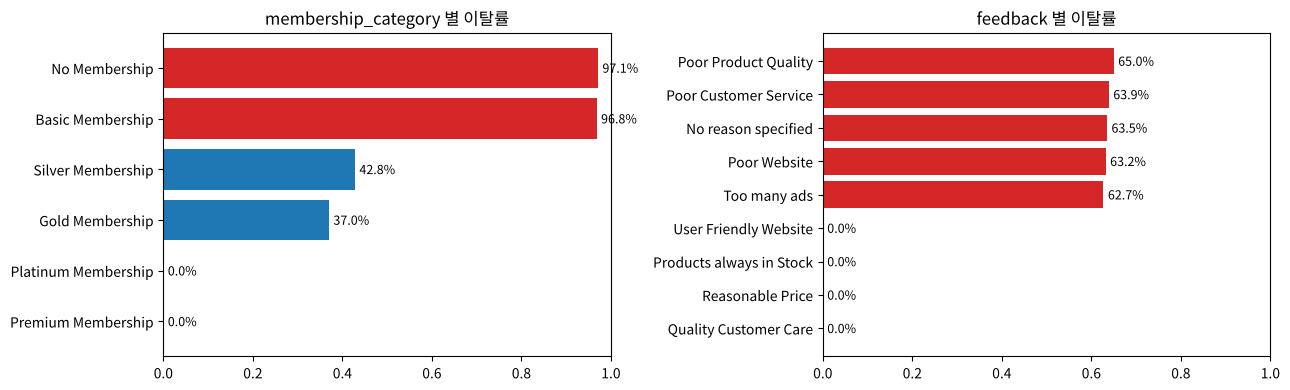

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ['membership_category', 'feedback']):
    t = rate_table(col)['이탈률'].sort_values()
    ax.barh(t.index, t.values, color=['tab:red' if v > 0.5 else 'tab:blue' for v in t.values])
    ax.set_xlim(0, 1); ax.set_title(f'{col} 별 이탈률')
    for i, v in enumerate(t.values):
        ax.text(v + 0.01, i, f'{v:.1%}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

- **Platinum · Premium = 이탈 0%**, **No · Basic = 97%** — 멤버십 하나로 절반 이상의 고객이 거의 결정된다
- **긍정 피드백 4종 = 이탈 0%**, 부정 · 없음은 63~65% 로 서로 비슷 → 팀이 9종을 `positive / negative / none` 3그룹으로 묶은 이유
- 성별 · 지역 · 가입 경로 · 접속 기기 등은 아래처럼 이탈률 차이가 거의 없다 (팀 README 결론과 같음)

In [8]:
others = ['gender', 'region_category', 'joined_through_referral', 'preferred_offer_types',
          'medium_of_operation', 'internet_option', 'used_special_discount', 'past_complaint', 'complaint_status']
spread = {c: df.groupby(c)[TARGET].mean().agg(lambda s: s.max() - s.min()) for c in others + ['membership_category', 'feedback']}
pd.Series(spread, name='그룹 간 이탈률 차이 (최대 − 최소)').sort_values(ascending=False).round(3).to_frame()

,그룹 간 이탈률 차이 (최대 − 최소)
membership_category,0.971
feedback,0.650
preferred_offer_types,0.054
gender,0.052
region_category,0.037
joined_through_referral,0.036
medium_of_operation,0.032
complaint_status,0.013
used_special_discount,0.011
internet_option,0.009


## 4. 수치형 — 포인트 · 평균 거래 금액 · 로그인 빈도

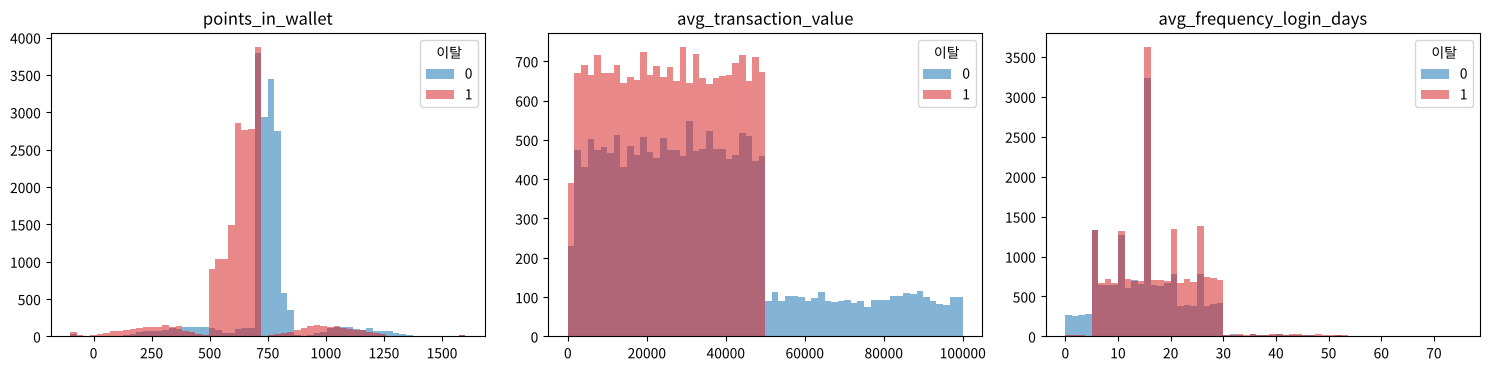

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, rng in zip(axes, ['points_in_wallet', 'avg_transaction_value', 'avg_frequency_login_days'],
                        [(-100, 1600), (0, 100000), (0, 75)]):
    for lab, c in [(0, 'tab:blue'), (1, 'tab:red')]:
        ax.hist(df.loc[df[TARGET] == lab, col].clip(*rng), bins=60, alpha=0.55, color=c, label=f'{lab}', range=rng)
    ax.set_title(col); ax.legend(title='이탈')
plt.tight_layout(); plt.show()

In [10]:
# 팀 대시보드(이탈 원인 분석 페이지)와 같은 4분위 구간
def quartile(s):
    return pd.qcut(s.rank(method='first'), 4, labels=['하위 25%', '중하위 25%', '중상위 25%', '상위 25%'])

print(df.groupby(quartile(df['points_in_wallet']), observed=True)[TARGET].mean().round(3).to_dict())
print(df.groupby(quartile(df['avg_transaction_value']), observed=True)[TARGET].mean().round(3).to_dict())

big = df['avg_transaction_value'] > 50000
print(f'평균 거래 금액 50,000 초과 : {big.sum():,}명, 이탈률 {df.loc[big, TARGET].mean():.3f}')

{'하위 25%': 0.832, '중하위 25%': 0.886, '중상위 25%': 0.266, '상위 25%': 0.18}
{'하위 25%': 0.591, '중하위 25%': 0.585, '중상위 25%': 0.581, '상위 25%': 0.406}
평균 거래 금액 50,000 초과 : 2,874명, 이탈률 0.000


In [11]:
# 포인트를 잘게 나누면 700 근처에서 이탈률이 '계단'처럼 꺾인다
bins = [-1e9, 500, 650, 697.6, 697.7, 710, 750, 850, 1e9]
labels = ['~500', '500~650', '650~697.6', '697.62 (채운 값)', '697.7~710', '710~750', '750~850', '850~']
df.groupby(pd.cut(df['points_in_wallet'], bins, labels=labels), observed=True)[TARGET].agg(고객수='size', 이탈률='mean').round(3)

,고객수,이탈률
points_in_wallet,,
~500,2815,0.568
500~650,9052,0.954
650~697.6,4905,0.958
697.62 (채운 값),3452,0.544
697.7~710,1863,0.466
710~750,4810,0.138
750~850,7233,0.016
850~,2862,0.542


- 포인트 **500~697점 이탈 95%**, **750~850점 이탈 1.6%** — 경계가 아주 날카롭다. 단, 500점 이하 · 850점 초과는 다시 50% 대 (단조롭지 않음 → 직선 하나로는 못 나누고 **비선형** 모델이 필요)
- 평균 거래 금액은 하위 3구간이 58~59% 로 비슷하고 **상위 25% 만 41%**, 특히 **50,000 초과 2,874명은 이탈 0%** (README '50,000 초과에서 이탈 고객이 보이지 않는다' 와 같음)

![포인트 경계 애니메이션](./images/anim_02_points_threshold.gif)

## 5. 규칙으로 정리 — 모델이 '진짜로' 판단해야 하는 고객

In [12]:
pd.crosstab(df['membership_category'], df['feedback_group'], values=df[TARGET], aggfunc='mean').round(3)

feedback_group,negative,none,positive
membership_category,,,
Basic Membership,0.967,0.969,NaN
Gold Membership,0.480,0.454,0.0
No Membership,0.971,0.970,NaN
Platinum Membership,0.000,0.000,0.0
Premium Membership,0.000,0.000,0.0
Silver Membership,0.490,0.476,0.0


In [13]:
easy0 = df['membership_category'].isin(['Platinum Membership', 'Premium Membership']) | (df['feedback_group'] == 'positive') \
        | (df['avg_transaction_value'] > 50000)
easy1 = df['membership_category'].isin(['No Membership', 'Basic Membership']) & ~easy0
hard = ~easy0 & ~easy1
for name, m in [('확실한 유지 (Platinum·Premium / 긍정 피드백 / 거래 5만 초과)', easy0),
                ('거의 이탈 (No·Basic)', easy1), ('애매한 고객 (Gold·Silver + 부정/없음)', hard)]:
    print(f'{name:45s} {m.sum():6,}명 ({m.mean():.1%})  이탈률 {df.loc[m, TARGET].mean():.3f}')

확실한 유지 (Platinum·Premium / 긍정 피드백 / 거래 5만 초과) 11,032명 (29.8%)  이탈률 0.000
거의 이탈 (No·Basic)                              15,416명 (41.7%)  이탈률 0.969
애매한 고객 (Gold·Silver + 부정/없음)                  10,544명 (28.5%)  이탈률 0.481


In [14]:
# 거래 금액 5만 초과 고객은 다른 조건과 겹칠까?
big = df['avg_transaction_value'] > 50000
covered = df['membership_category'].isin(['Platinum Membership', 'Premium Membership']) | (df['feedback_group'] == 'positive')
print(f'거래 5만 초과 {big.sum():,}명 중 이미 Platinum·Premium 또는 긍정 피드백 : {(big & covered).sum():,}명 ({(big & covered).sum() / big.sum():.0%})')

거래 5만 초과 2,874명 중 이미 Platinum·Premium 또는 긍정 피드백 : 2,874명 (100%)


- 고객의 약 **70%** 는 멤버십 · 피드백만으로 거의 정답이 정해진다. **거래 5만 초과 2,874명은 전원이 이미 Platinum·Premium 이거나 긍정 피드백** — '거래 금액이 크면 이탈 0%' 는 새로운 정보가 아니라 같은 고객을 다르게 본 것이다
- 나머지 **Gold · Silver + 부정/없음 피드백** 고객은 이탈률이 중간이라, 여기서 **포인트**가 결정적인 역할을 한다 → 모델 성능의 차이는 대부분 이 그룹에서 난다

## 6. 수치형 변수 상관

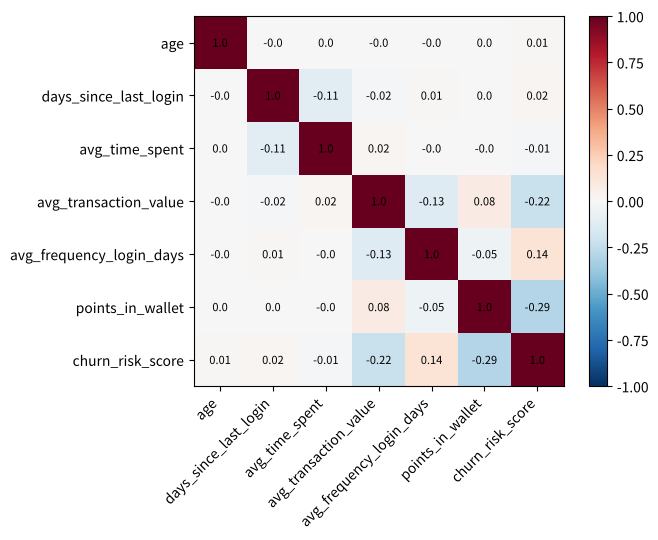

정답과의 상관 : {'points_in_wallet': -0.29, 'avg_transaction_value': -0.22, 'avg_time_spent': -0.01, 'age': 0.01, 'days_since_last_login': 0.02, 'avg_frequency_login_days': 0.14}


In [15]:
corr = df[num_cols + [TARGET]].corr().round(2)
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right'); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.iloc[i, j], ha='center', va='center', fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.show()
print('정답과의 상관 :', corr[TARGET].drop(TARGET).sort_values().to_dict())

수치형끼리 상관은 거의 0 → README 결론대로 다중공선성 걱정은 없다. 정답과의 **선형** 상관도 포인트 −0.29 · 거래 금액 −0.22 · 로그인 지표 0.14 로 약한 편이지만, 4절처럼 **구간별**로 보면 강한 관계가 숨어 있다 (상관계수는 직선 관계만 잰다).

## 📝 점검 정리

| 항목 | 팀 결과 / 코드 | 점검 |
|---|---|---|
| 포인트 결측 | 중앙값 대체 | 697.62 에 3,446명(9.3%) 몰림 → 결측 표시 열 추가 제안 |
| 포인트 음수 | 그대로 | 136명 — 음수 포인트는 불가능한 값, 결측 처리 대상 |
| 핵심 요인 | 멤버십 · 포인트 · 거래 금액 · 피드백 | ✔ 데이터로 확인 (Platinum·Premium · 긍정 피드백 · 거래 5만 초과 = 이탈 0%) |
| 다중공선성 | 걱정 없음 | ✔ 수치형 상관 거의 0 |
| 데이터 성격 | — | 규칙이 거의 정해진 데이터라 정확도가 높게 나오기 쉽다 → 단순 모델과 꼭 비교 ([`churn_project_mlp.ipynb`](./churn_project_mlp.ipynb)) |